# 🎯 Evaluation Metrics for Binary Classification

*How good is my classifier, really?*

We train a logistic regression model that predicts whether a telecom customer will **churn** (leave the company), and then use it as a running example to study, step by step, **how to evaluate a binary classifier**:

| # | Section | What you will learn |
|---|---------|---------------------|
| 1 | Setup | Libraries, colors and a small plotting helper |
| 2 | Data and a first model | The churn dataset, a 60/20/20 split, logistic regression |
| 3 | Accuracy | Definition, the decision threshold, and the **accuracy paradox** on imbalanced data |
| 4 | Confusion matrix | TP, TN, FP, FN with **Venn-style diagrams**, a short detour to multiclass problems |
| 5 | Precision, recall and F1 | Formulas, diagrams, intuition, the trade-off, PR curve, cost-based thresholds, and **answers to common questions** |
| 6 | ROC curve | TPR and FPR as functions of the threshold, built **from scratch** |
| 7 | Random and ideal models | The two reference curves every ROC plot is compared with |
| 8 | AUC | Area under the ROC curve, and a **proof** of its probabilistic interpretation |
| 9 | k-fold cross-validation | Estimating performance *and its uncertainty*, tuning `C`, final test evaluation |
| 10 | Summary | A cheat sheet of all metrics |

**Convention.** Throughout the notebook the *positive class* ($y = 1$) is **"the customer churns"** and the negative class ($y = 0$) is **"the customer stays"**. "Positive" therefore does not mean "good"; it means "the event we are trying to detect".

### Notation

| Symbol | Meaning |
|--------|---------|
| $n$ | number of examples in the evaluated set |
| $n_+,\ n_-$ | number of actual positives (churners) and actual negatives (stayers), $n = n_+ + n_-$ |
| $\pi = n_+/n$ | **prevalence**: the fraction of positives |
| $s(x) \in [0, 1]$ | the model's **score** for example $x$; here the predicted probability $P(y=1 \mid x)$ |
| $t$ | decision **threshold** |
| $\hat y = \mathbb{1}[\,s(x) > t\,]$ | the predicted class |

---
## 1. Setup

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, Rectangle
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    multilabel_confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold, train_test_split

SEED = 1
rng = np.random.default_rng(SEED)  # one random generator for the whole notebook -> reproducible results

# Colors used consistently in every figure
C_STAY = "#2a78d6"    # class 0, the customer stays   (blue)
C_CHURN = "#eb6834"   # class 1, the customer churns  (orange)
C_GREEN = "#1baf7a"   # "ideal" model, F1 score       (aqua)
C_GRAY = "#8a8985"    # baselines, random model
C_YELLOW = "#eda100"
C_RED = "#e34948"
C_VIOLET = "#6250d6"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

# Figures used in the README are also saved to images/
IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)


def savefig(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=120, bbox_inches="tight")

---
## 2. Data and a first model

We use the [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) dataset: 7,043 customers described by 19 features (contract type, tenure, monthly charges, services, ...) and a `Churn` label. The data preparation is kept to the minimum here, because this notebook is about *evaluation*.

* `TotalCharges` is stored as text and contains blanks for brand-new customers (tenure 0); we convert it to a number and fill the blanks with 0.
* `Churn` is converted from `"Yes"`/`"No"` to `1`/`0`.

In [2]:
df = pd.read_csv("data/churn_telco_data.csv")

df.TotalCharges = pd.to_numeric(df.TotalCharges, errors="coerce").fillna(0)
df.Churn = (df.Churn == "Yes").astype(int)

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Train / validation / test split (60 % / 20 % / 20 %)

1. `train_test_split(df, test_size=0.20)` keeps 20 % of the data as the **test set**. It is shuffled (with a fixed seed) and is not touched until the very end.
2. The remaining 80 % (`df_train_full`) is split again into **train** and **validation**. `test_size=0.25` because $0.25 \times 80\,\% = 20\,\%$ of the original data. `df_train_full` is already shuffled by step 1, so `shuffle=False` simply takes its last quarter as the validation set.

In [3]:
df_train_full, df_test = train_test_split(df, test_size=0.20, random_state=SEED)
df_train, df_valid = train_test_split(df_train_full, test_size=0.25, shuffle=False)

y_train_full = df_train_full.Churn.values
y_train = df_train.Churn.values
y_valid = df_valid.Churn.values
y_test = df_test.Churn.values

print(f"train: {len(df_train)}   validation: {len(df_valid)}   test: {len(df_test)}")

train: 4225   validation: 1409   test: 1409


### Features and model

* `Churn` is the label, so it is **not** a feature.
* `customerID` is just an identifier; it says nothing about the customer's behavior, so it is dropped too.
* `DictVectorizer` one-hot encodes the categorical columns and passes the numeric ones through unchanged.

In [4]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in df.columns if c not in numeric_features + ["Churn", "customerID"]]
features = categorical_features + numeric_features

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
X_val = dv.transform(df_valid[features].to_dict(orient="records"))

model = LogisticRegression(random_state=SEED, max_iter=5000).fit(X_train, y_train)

# The predicted churn probabilities on the validation set. Every metric below is computed from them.
y_proba = model.predict_proba(X_val)[:, 1]

print(f"{X_train.shape[1]} features after one-hot encoding")
y_proba[:10].round(3)

45 features after one-hot encoding


array([0.109, 0.164, 0.015, 0.777, 0.297, 0.02 , 0.297, 0.75 , 0.683,
       0.344])

---
## 3. Accuracy

Let's start with the simplest and most widely used metric: the fraction of correct predictions.

$$
\text{accuracy} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\hat y_i = y_i\right]
$$

In [5]:
print("model.score     :", model.score(X_val, y_valid))                     # scikit-learn's built-in accuracy
print("from scratch    :", (model.predict(X_val) == y_valid).mean())        # mean of a boolean array = fraction of True
print("accuracy_score  :", accuracy_score(y_valid, model.predict(X_val)))

model.score     : 0.8019872249822569
from scratch    : 0.8019872249822569
accuracy_score  : 0.8019872249822569


### 3.1 The decision threshold

A logistic regression does not output classes but **probabilities**. `model.predict` turns them into classes with the threshold $t = 0.5$:

$$
\hat y = \mathbb{1}[\,s(x) > t\,], \qquad t = 0.5 .
$$

We can reproduce `model.predict` ourselves, and then ask: **is 0.5 the best threshold for accuracy?**

In [6]:
print("threshold 0.5 by hand:", ((y_proba > 0.5) == y_valid).mean())

thresholds = np.linspace(0, 1, 1001)
accuracies = np.array([((y_proba > t) == y_valid).mean() for t in thresholds])

best = accuracies.argmax()
print(f"best threshold: {thresholds[best]:.3f}  ->  accuracy {accuracies[best]:.4f}")

threshold 0.5 by hand: 0.8019872249822569
best threshold: 0.505  ->  accuracy 0.8048


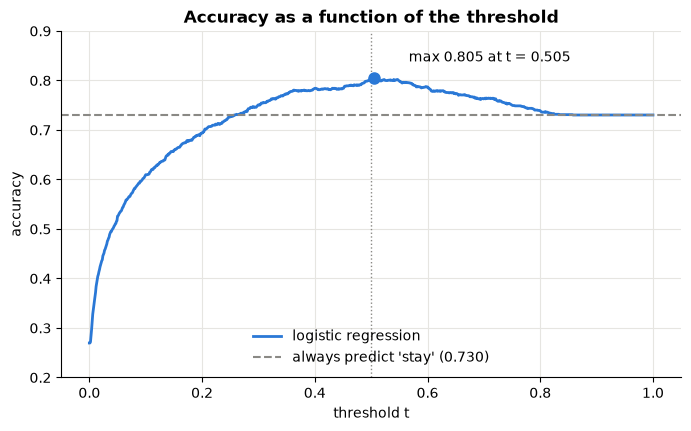

In [7]:
baseline_acc = (y_valid == 0).mean()  # accuracy of "always predict stay" (see 3.2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, accuracies, color=C_STAY, label="logistic regression")
ax.axhline(baseline_acc, color=C_GRAY, linestyle="--", linewidth=1.5, label=f"always predict 'stay' ({baseline_acc:.3f})")
ax.axvline(0.5, color=C_GRAY, linewidth=1, linestyle=":")
ax.plot(thresholds[best], accuracies[best], "o", color=C_STAY, markersize=8)
ax.annotate(f"max {accuracies[best]:.3f} at t = {thresholds[best]:.3f}", (thresholds[best], accuracies[best]),
            xytext=(25, 12), textcoords="offset points")
ax.set(xlabel="threshold t", ylabel="accuracy", title="Accuracy as a function of the threshold", ylim=(0.2, 0.9))
ax.legend(loc="lower center")
plt.show()

**Observations**

* The curve is flat around $t = 0.5$; the best threshold improves accuracy by only a few tenths of a percent.
* At $t = 0$ every customer is predicted to churn: accuracy is the share of churners $\pi$.
* At $t = 1$ nobody is predicted to churn: accuracy becomes the share of non-churners $1 - \pi \approx 0.73$.

Moving the threshold a little only changes the predictions of customers whose probability is close to it, and there are few of them:

97 of 1409 customers have a churn probability between 0.45 and 0.55


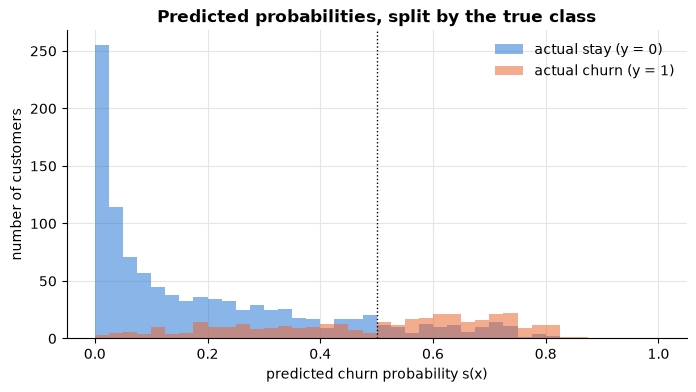

In [8]:
near_half = ((y_proba > 0.45) & (y_proba < 0.55)).sum()
print(f"{near_half} of {len(y_proba)} customers have a churn probability between 0.45 and 0.55")

bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_proba[y_valid == 0], bins=bins, color=C_STAY, alpha=0.55, label="actual stay (y = 0)")
ax.hist(y_proba[y_valid == 1], bins=bins, color=C_CHURN, alpha=0.55, label="actual churn (y = 1)")
ax.axvline(0.5, color="black", linewidth=1, linestyle=":")
ax.set(xlabel="predicted churn probability s(x)", ylabel="number of customers",
       title="Predicted probabilities, split by the true class")
ax.legend()
savefig(fig, "score_distributions")
plt.show()

This histogram is worth remembering: **every metric in this notebook is just a different way of summarizing how well these two distributions are separated.** Everything to the right of the threshold is predicted "churn", everything to the left "stay".

### 3.2 The accuracy paradox: imbalanced classes

Imagine a *dummy model* that ignores the input and always predicts "stay":

In [9]:
print("class counts in the validation set:", Counter(y_valid.tolist()))

dummy_pred = np.zeros_like(y_valid)
print("accuracy of the dummy model      :", (dummy_pred == y_valid).mean())

# The same thing via the threshold: no probability is > 1, so everybody is predicted "stay"
print("accuracy with threshold t = 1    :", ((y_proba > 1) == y_valid).mean())

class counts in the validation set: Counter({0: 1029, 1: 380})
accuracy of the dummy model      : 0.730305180979418
accuracy with threshold t = 1    : 0.730305180979418


A model that has learned **nothing** reaches 73 % accuracy, because the data are **imbalanced**: only $\pi \approx 27\,\%$ of the customers churn. In general the "always predict the majority class" model has

$$
\text{accuracy}_{\text{dummy}} = \max(\pi,\ 1 - \pi),
$$

so on a dataset with 1 % positives (fraud, rare diseases, ...) a useless model has 99 % accuracy. This is called the **accuracy paradox**.

Our model's 80.2 % should therefore be read *relative to the 73.0 % baseline*: the error rate goes from 27.0 % to 19.8 %, i.e. the model removes about a quarter of the dummy model's mistakes. That is useful, but far less impressive than "80 % accuracy" sounds.

To understand *what kind* of mistakes a model makes we need to look inside the accuracy: this is what the confusion matrix does. (The other remedy, re-balancing the data, changes the training, not the evaluation, so it is out of scope here.)

---
## 4. The confusion matrix

Every prediction falls into exactly one of four groups. The name has two parts: the **second** word is what the model *predicted* (Positive / Negative), the **first** word tells whether that prediction was *correct* (True / False).

| | predicted stay ($\hat y = 0$) | predicted churn ($\hat y = 1$) |
|---|:---:|:---:|
| **actual stay** ($y = 0$) | **TN**: true negative | **FP**: false positive *(false alarm, type I error)* |
| **actual churn** ($y = 1$) | **FN**: false negative *(miss, type II error)* | **TP**: true positive |

$$
\text{TP} = \sum_i \mathbb{1}[\hat y_i = 1,\ y_i = 1] \qquad
\text{TN} = \sum_i \mathbb{1}[\hat y_i = 0,\ y_i = 0] \qquad
\text{FP} = \sum_i \mathbb{1}[\hat y_i = 1,\ y_i = 0] \qquad
\text{FN} = \sum_i \mathbb{1}[\hat y_i = 0,\ y_i = 1]
$$

with $\text{TP} + \text{TN} + \text{FP} + \text{FN} = n$.

In [10]:
y_pred = (y_proba > 0.5).astype(int)

TP = ((y_pred == 1) & (y_valid == 1)).sum()   # predicted churn, and really churned
TN = ((y_pred == 0) & (y_valid == 0)).sum()   # predicted stay,  and really stayed
FP = ((y_pred == 1) & (y_valid == 0)).sum()   # predicted churn, but stayed
FN = ((y_pred == 0) & (y_valid == 1)).sum()   # predicted stay,  but churned

# Equivalent formulation: "correct and predicted 1" is the same as "predicted 1 and true 1"
assert TP == ((y_pred == y_valid) & (y_pred == 1)).sum()
assert TP + TN + FP + FN == len(y_valid)

print(f"TP = {TP}   TN = {TN}   FP = {FP}   FN = {FN}")

TP = 211   TN = 919   FP = 110   FN = 169


### 4.1 A picture of the four groups

The diagram below is the classic way to visualize them:

* the **square** contains all customers of the validation set,
* the **left half** holds the customers who actually churned ($y = 1$), the **right half** those who stayed ($y = 0$),
* the **circle** holds the customers the model *flags* as churners ($\hat y = 1$).

The circle cuts the square into four regions, one for each cell of the confusion matrix. (The areas are not to scale.)

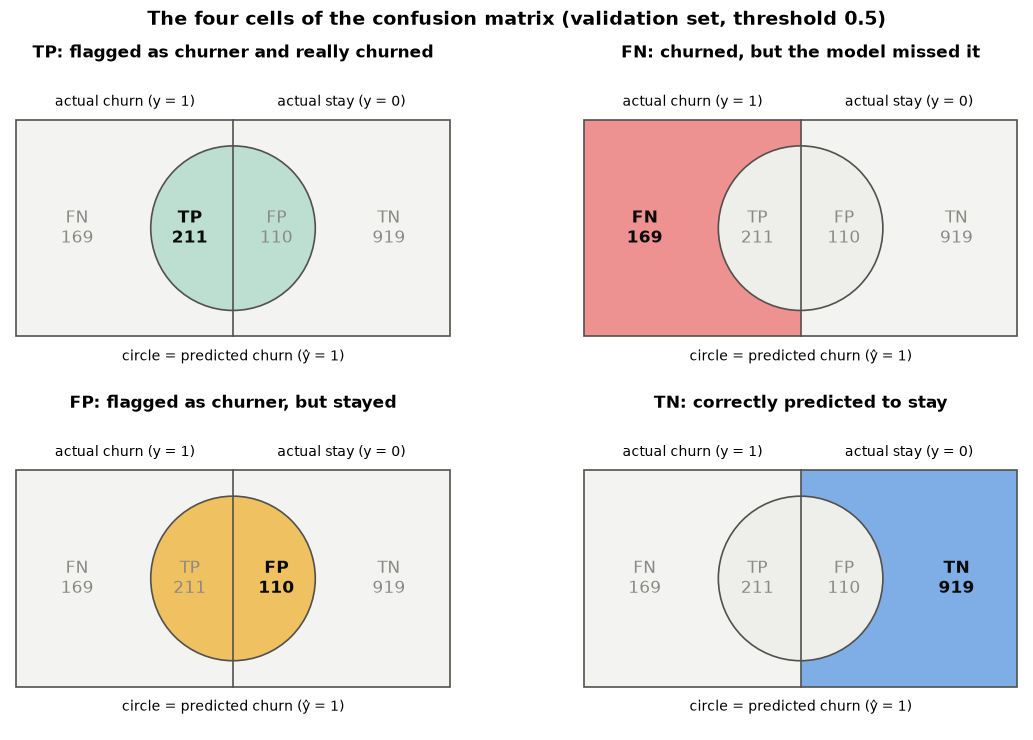

In [11]:
REGION_COLORS = {"TP": C_GREEN, "FN": C_RED, "FP": C_YELLOW, "TN": C_STAY}
REGION_TEXT_POS = {"TP": (0.80, 0.5), "FP": (1.20, 0.5), "FN": (0.28, 0.5), "TN": (1.72, 0.5)}
MUTED = "#ecebe8"


def draw_confusion_diagram(ax, counts, highlight=("TP", "TN", "FP", "FN"), outline=None, title=None):
    # Square = all examples, left half = actual positives, circle = predicted positives.
    # `highlight`: regions drawn in color (the others are muted).
    # `outline`  : "circle", "left" or "all": the region drawn with a thick border (a denominator).
    color = lambda r: REGION_COLORS[r] if r in highlight else MUTED
    left = Rectangle((0, 0), 1, 1, transform=ax.transData)
    right = Rectangle((1, 0), 1, 1, transform=ax.transData)

    ax.add_patch(Rectangle((0, 0), 1, 1, facecolor=color("FN"), alpha=0.6, linewidth=0))
    ax.add_patch(Rectangle((1, 0), 1, 1, facecolor=color("TN"), alpha=0.6, linewidth=0))
    for region, clip in [("TP", left), ("FP", right)]:
        c = Circle((1, 0.5), 0.38, facecolor="white", linewidth=0, zorder=2)
        c.set_clip_path(clip)
        ax.add_patch(c)
        c = Circle((1, 0.5), 0.38, facecolor=color(region), alpha=0.6, linewidth=0, zorder=3)
        c.set_clip_path(clip)
        ax.add_patch(c)

    ax.add_patch(Rectangle((0, 0), 2, 1, fill=False, edgecolor="#52514e", linewidth=1.2, zorder=4))
    ax.plot([1, 1], [0, 1], color="#52514e", linewidth=1.2, zorder=4)
    ax.add_patch(Circle((1, 0.5), 0.38, fill=False, edgecolor="#52514e", linewidth=1.2, zorder=4))
    if outline == "circle":
        ax.add_patch(Circle((1, 0.5), 0.38, fill=False, edgecolor="black", linewidth=3.5, zorder=5))
    elif outline == "left":
        ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, edgecolor="black", linewidth=3.5, zorder=5))
    elif outline == "all":
        ax.add_patch(Rectangle((0, 0), 2, 1, fill=False, edgecolor="black", linewidth=3.5, zorder=5))

    for region, (x, y) in REGION_TEXT_POS.items():
        weight = "bold" if region in highlight else "normal"
        ink = "#0b0b0b" if region in highlight else "#8a8985"
        ax.text(x, y, f"{region}\n{counts[region]}", ha="center", va="center", fontsize=12,
                fontweight=weight, color=ink, zorder=6)

    ax.text(0.5, 1.05, "actual churn (y = 1)", ha="center", va="bottom", fontsize=10)
    ax.text(1.5, 1.05, "actual stay (y = 0)", ha="center", va="bottom", fontsize=10)
    ax.text(1.0, -0.06, "circle = predicted churn (ŷ = 1)", ha="center", va="top", fontsize=10)
    ax.set(xlim=(-0.03, 2.03), ylim=(-0.2, 1.25), aspect="equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12)


counts = {"TP": TP, "TN": TN, "FP": FP, "FN": FN}
descriptions = {
    "TP": "TP: flagged as churner and really churned",
    "FN": "FN: churned, but the model missed it",
    "FP": "FP: flagged as churner, but stayed",
    "TN": "TN: correctly predicted to stay",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, region in zip(axes.ravel(), ["TP", "FN", "FP", "TN"]):
    draw_confusion_diagram(ax, counts, highlight=(region,), title=descriptions[region])
fig.suptitle("The four cells of the confusion matrix (validation set, threshold 0.5)", fontsize=14, fontweight="bold")
fig.tight_layout()
savefig(fig, "confusion_venn")
plt.show()

### 4.2 With scikit-learn

`confusion_matrix` puts the **true** classes in the rows and the **predicted** classes in the columns, both sorted (0 first):

$$
\begin{pmatrix} \text{TN} & \text{FP} \\ \text{FN} & \text{TP} \end{pmatrix}
$$

so `.ravel()` returns the four counts in the order `tn, fp, fn, tp`.

In [12]:
cm = confusion_matrix(y_true=y_valid, y_pred=y_pred)
tn, fp, fn, tp = cm.ravel().tolist()

assert (tn, fp, fn, tp) == (TN, FP, FN, TP)
assert tn + fp + fn + tp == len(y_pred)
cm

array([[919, 110],
       [169, 211]])

Dividing by $n$ gives the *fraction* of all customers in each cell. Dividing each **row** by its sum instead answers "of the customers who really stayed (churned), which fraction did the model classify as stay / churn?". The bottom-right entry of the row-normalized matrix is the **recall** (section 5) and the top-right one the **false positive rate** (section 6).

normalized by the total:
 [[0.652 0.078]
 [0.12  0.15 ]]


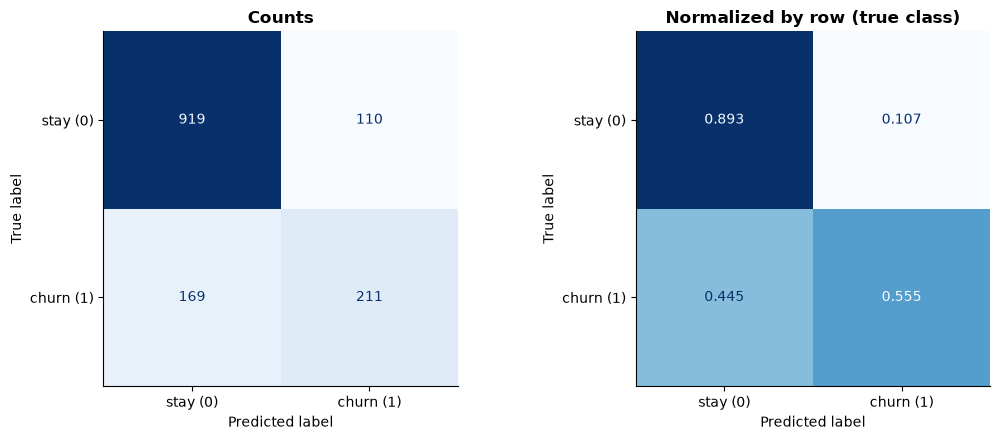

In [13]:
print("normalized by the total:\n", (cm / cm.sum()).round(3))

labels = ["stay (0)", "churn (1)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_valid, y_pred, display_labels=labels, cmap="Blues",
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_valid, y_pred, display_labels=labels, cmap="Blues",
                                        normalize="true", values_format=".3f", colorbar=False, ax=axes[1])
axes[1].set_title("Normalized by row (true class)")
for ax in axes:
    ax.grid(False)
fig.tight_layout()
savefig(fig, "confusion_matrix")
plt.show()

### 4.3 A detour: confusion matrices for more than two classes

For $K$ classes the confusion matrix is $K \times K$. To talk about TP, FP, FN and TN we look at one class at a time, **one-vs-rest**: class $k$ is "positive", all other classes together are "negative". `multilabel_confusion_matrix` returns one $2 \times 2$ matrix per class.

In [14]:
y_true_mc = np.array([2, 0, 2, 2, 0, 1])
y_pred_mc = np.array([0, 0, 2, 2, 0, 2])

print("full 3 x 3 confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_true_mc, y_pred_mc, labels=[0, 1, 2]))

matrices = multilabel_confusion_matrix(y_true_mc, y_pred_mc, labels=[0, 1, 2])
pd.DataFrame([m.ravel() for m in matrices], columns=["tn", "fp", "fn", "tp"],
             index=pd.Index([0, 1, 2], name="positive class"))

full 3 x 3 confusion matrix (rows = true, columns = predicted):
[[2 0 0]
 [0 0 1]
 [1 0 2]]


,tn,fp,fn,tp
positive class,,,,
0,3,1,0,2
1,5,0,1,0
2,2,1,1,2


**Why is `fn = 0` for class 0, and not 1?** A natural first guess is: "sample 5 has true label 1 and was predicted as 2, so it is a false negative for class 0". But in the one-vs-rest view for class 0, sample 5 is *negative* both in truth (1 ≠ 0) and in the prediction (2 ≠ 0), so it is a **true negative for class 0**. The same mistake counts as:

* a **false negative for class 1** (its true class was missed), and
* a **false positive for class 2** (the class it was wrongly assigned to).

In general, every misclassified sample is counted exactly **once as an FN** (for its true class) and **once as an FP** (for its predicted class), and as a TN for all other classes. Hence

$$
\sum_k \text{FN}_k = \sum_k \text{FP}_k = \text{number of errors}.
$$

Here that is 2 errors (samples 0 and 5): $\text{FN} = 0 + 1 + 1$ and $\text{FP} = 1 + 0 + 1$.

---
## 5. Accuracy, precision and recall

All three are ratios of confusion-matrix cells:

$$
\text{accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}
\qquad
\text{precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
\qquad
\text{recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}
$$

* **Precision** answers: *of the customers the model flagged as churners, which fraction really churned?* Its denominator is the **circle** (everything predicted positive).
* **Recall** (also *sensitivity* or *true positive rate*) answers: *of the customers who really churned, which fraction did the model find?* Its denominator is the **left half** (everything actually positive).
* **Accuracy** looks at the **whole square**.

In [15]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)

print(f"accuracy  = {accuracy:.4f}   (sklearn: {accuracy_score(y_valid, y_pred):.4f})")
print(f"precision = {precision:.4f}   (sklearn: {precision_score(y_valid, y_pred):.4f})")
print(f"recall    = {recall:.4f}   (sklearn: {recall_score(y_valid, y_pred):.4f})")

accuracy  = 0.8020   (sklearn: 0.8020)
precision = 0.6573   (sklearn: 0.6573)
recall    = 0.5553   (sklearn: 0.5553)


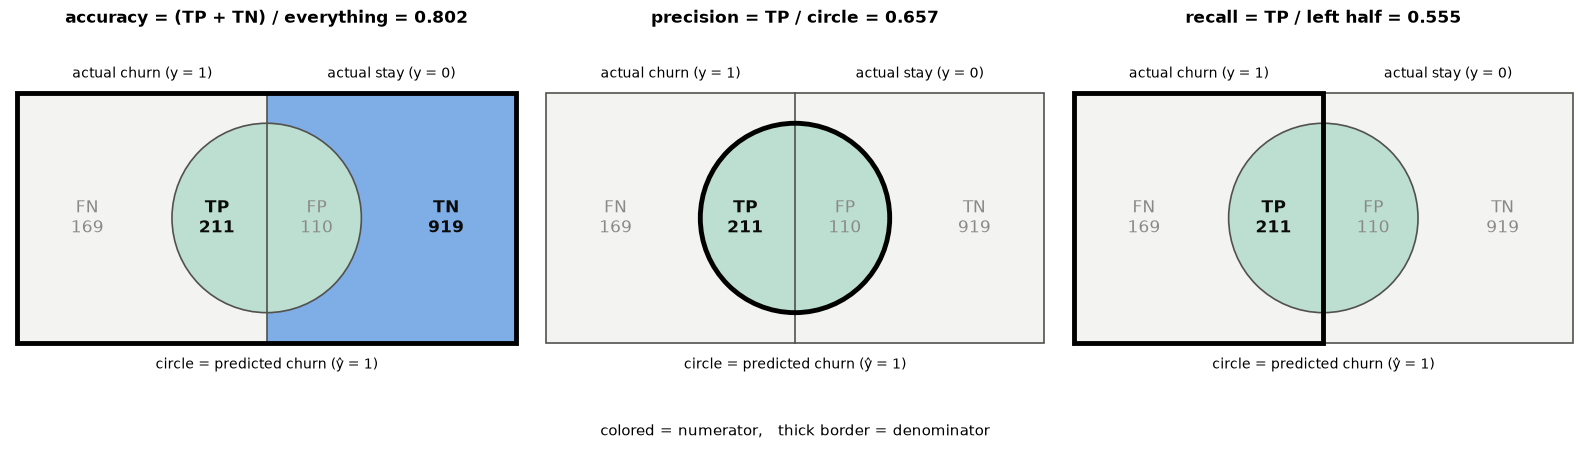

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
draw_confusion_diagram(axes[0], counts, highlight=("TP", "TN"), outline="all",
                       title=f"accuracy = (TP + TN) / everything = {accuracy:.3f}")
draw_confusion_diagram(axes[1], counts, highlight=("TP",), outline="circle",
                       title=f"precision = TP / circle = {precision:.3f}")
draw_confusion_diagram(axes[2], counts, highlight=("TP",), outline="left",
                       title=f"recall = TP / left half = {recall:.3f}")
fig.text(0.5, -0.02, "colored = numerator,   thick border = denominator", ha="center", fontsize=11)
fig.tight_layout()
savefig(fig, "precision_recall_venn")
plt.show()

### 5.1 Precision alone is not enough: a precise but useless model

A precise model is like a very cautious student who only answers the questions they are absolutely sure about: almost every answer is correct, but most questions stay unanswered. Precision **ignores the false negatives** (the left part outside the circle), so a model can make its precision high simply by flagging very few customers.

Let's build such a model: flag only the $k$ customers with the highest predicted probability.

In [17]:
order = np.argsort(-y_proba)  # customers sorted from most to least likely to churn

rows = []
for k in [1, 5, 20, 50, 100, 300]:
    y_hat_k = np.zeros_like(y_valid)
    y_hat_k[order[:k]] = 1
    rows.append((k, precision_score(y_valid, y_hat_k), recall_score(y_valid, y_hat_k)))

pd.DataFrame(rows, columns=["customers flagged", "precision", "recall"]).round(3)

,customers flagged,precision,recall
0,1,1.000,0.003
1,5,1.000,0.013
2,20,0.850,0.045
3,50,0.820,0.108
4,100,0.730,0.192
5,300,0.663,0.524


Flagging only the single most suspicious customer gives **100 % precision**, but a recall of $1/380 \approx 0.3\,\%$: the retention team would contact one customer and lose the other 379 churners. Perfectly precise, completely useless.

### 5.2 Recall alone is not enough: the "everybody churns" model

Now the opposite extreme: predict **everyone** as a churner. Then nobody is predicted negative, so $\text{FN} = 0$ and

$$
\text{recall} = \frac{\text{TP}}{\text{TP} + 0} = 1 ,
\qquad
\text{precision} = \frac{n_+}{n} = \pi \approx 0.27 .
$$

The circle has swallowed the whole square: every churner is found, but 73 % of the discounts go to customers who were never going to leave.

In [18]:
y_all_churn = np.ones_like(y_valid)
print("recall   :", recall_score(y_valid, y_all_churn))
print("precision:", round(precision_score(y_valid, y_all_churn), 4), "= prevalence", round(y_valid.mean(), 4))

recall   : 1.0
precision: 0.2697 = prevalence 0.2697


Precision and recall pull in **opposite directions**: a higher threshold shrinks the circle (fewer, more confident flags → precision ↑, recall ↓), a lower threshold grows it (precision ↓, recall ↑). We always have to look at both, or at a metric that combines them (section 5.4).

### 5.3 Questions and answers

#### Q1. What is the difference between precision and accuracy? The names suggest they are the same thing.

In everyday language (and in measurement science) they are different ideas: *accuracy* is how close measurements are to the true value, *precision* is how close repeated measurements are to each other. Machine learning re-uses the two words for two **different ratios**, so the everyday meaning does not help much.

The good intuition is the one in the question: **precision is accuracy restricted to the predicted positives.** In fact, each of the common metrics is "the accuracy on one part of the square":

| metric | formula | accuracy computed on ... |
|---|---|---|
| accuracy | $(\text{TP}+\text{TN})/n$ | everybody |
| precision | $\text{TP}/(\text{TP}+\text{FP})$ | customers **predicted** to churn (the circle) |
| negative predictive value (NPV) | $\text{TN}/(\text{TN}+\text{FN})$ | customers **predicted** to stay |
| recall / sensitivity / TPR | $\text{TP}/(\text{TP}+\text{FN})$ | customers who **actually** churned (left half) |
| specificity / TNR | $\text{TN}/(\text{TN}+\text{FP})$ | customers who **actually** stayed (right half) |

And accuracy is a **weighted average** of these "partial accuracies". Splitting the square by the true class (weights $\pi$ and $1 - \pi$) or by the predicted class (weights $q$ and $1 - q$, with $q = (\text{TP}+\text{FP})/n$ the fraction predicted positive):

$$
\text{accuracy} = \pi \cdot \text{recall} + (1 - \pi)\cdot \text{specificity}
\qquad\text{and}\qquad
\text{accuracy} = q \cdot \text{precision} + (1 - q)\cdot \text{NPV}.
$$

With imbalanced data the weight $1 - \pi$ is large, so accuracy is dominated by how well the model handles the *majority* class, which is exactly why it is misleading.

In [19]:
n = len(y_valid)
pi = (tp + fn) / n            # prevalence
q = (tp + fp) / n             # fraction predicted positive
specificity = tn / (tn + fp)
npv = tn / (tn + fn)

print(f"accuracy                             = {accuracy:.6f}")
print(f"pi*recall + (1-pi)*specificity       = {pi * recall + (1 - pi) * specificity:.6f}")
print(f"q*precision + (1-q)*NPV              = {q * precision + (1 - q) * npv:.6f}")

accuracy                             = 0.801987
pi*recall + (1-pi)*specificity       = 0.801987
q*precision + (1-q)*NPV              = 0.801987


#### Q2. What is the relation between accuracy, precision and recall? Can we obtain one from the others?

Count the degrees of freedom. The confusion matrix has 4 cells that add up to $n$, so after dividing by $n$ it has **3 free numbers**. Write $a = \text{TP}/n$, $b = \text{FP}/n$, $c = \text{FN}/n$ (and $\text{TN}/n = 1 - a - b - c$). Then

$$
\text{precision} = P = \frac{a}{a+b}, \qquad \text{recall} = R = \frac{a}{a+c}, \qquad \text{accuracy} = A = 1 - b - c .
$$

* **From precision and recall alone you cannot get accuracy.** Precision and recall never use TN. Adding true negatives (stayers that the model correctly ignores) leaves $P$ and $R$ unchanged but increases $A$; see the example below.
* **With the prevalence $\pi = a + c$ as a third number, everything is determined.** From $R$: $a = R\pi$. From $P$: $b = a(1/P - 1)$. From $\pi$: $c = \pi - a$. Hence

$$
A = 1 - b - c = 1 - \pi\left(1 + \frac{R}{P} - 2R\right).
$$

* Similarly, $(A, P, R)$ together determine the whole normalized confusion matrix (as long as the model is not perfect): $b + c = 1 - A$ with $b = a(1/P - 1)$ and $c = a(1/R - 1)$ gives $a = \dfrac{1 - A}{1/P + 1/R - 2}$.

So the three metrics are **not independent**, but no single one can be computed from the other two without extra information about the data.

In [20]:
# Same precision and recall, very different accuracy: only TN differs
for TP_, FP_, FN_, TN_ in [(50, 50, 50, 50), (50, 50, 50, 850)]:
    P_, R_, A_ = TP_ / (TP_ + FP_), TP_ / (TP_ + FN_), (TP_ + TN_) / (TP_ + FP_ + FN_ + TN_)
    print(f"TP={TP_} FP={FP_} FN={FN_} TN={TN_:>3}:  precision={P_:.2f}  recall={R_:.2f}  accuracy={A_:.2f}")

# Accuracy recovered from precision, recall and prevalence on our validation set
print(f"\naccuracy from (P, R, pi): {1 - pi * (1 + recall / precision - 2 * recall):.6f}   direct: {accuracy:.6f}")

TP=50 FP=50 FN=50 TN= 50:  precision=0.50  recall=0.50  accuracy=0.50
TP=50 FP=50 FN=50 TN=850:  precision=0.50  recall=0.50  accuracy=0.90

accuracy from (P, R, pi): 0.801987   direct: 0.801987


#### Q3. $1 - \text{recall}$ is "the fraction of positives we failed to identify". What does $1 - \text{precision}$ mean?

$$
1 - \text{recall} = \frac{\text{FN}}{\text{TP} + \text{FN}} \quad\text{(false negative rate, miss rate)}
\qquad
1 - \text{precision} = \frac{\text{FP}}{\text{TP} + \text{FP}} \quad\text{(false discovery rate, FDR)}
$$

$1 - \text{precision}$ is the fraction of the model's **alarms that are false**: among all customers flagged as churners, the share who were not going to leave. In the diagram: the yellow part of the circle divided by the whole circle.

#### Q4. What do these numbers mean for the churn business?

Suppose the company offers a discount to every customer the model flags.

In [21]:
print(f"precision = {precision:.1%}  ->  1 - precision = {1 - precision:.1%} of the discounts go to customers "
      f"who were NOT going to leave (wasted money)")
print(f"recall    = {recall:.1%}  ->  1 - recall    = {1 - recall:.1%} of the churners get no discount "
      f"and are lost")

precision = 65.7%  ->  1 - precision = 34.3% of the discounts go to customers who were NOT going to leave (wasted money)
recall    = 55.5%  ->  1 - recall    = 44.5% of the churners get no discount and are lost


The two kinds of errors have different costs: a **false positive** costs one unnecessary discount, a **false negative** costs a lost customer (usually much more). Which of the two metrics matters more depends on these costs; section 5.5 turns this into a way of choosing the threshold.

#### Q5. Given all this, should we ignore accuracy completely? Does it give useful information?

No, but it must be read correctly.

* **Precision and recall only describe the positive class.** Neither of them contains TN. A model that handles the stayers badly is not visible in them, while accuracy (and specificity) see it.
* **Accuracy is meaningful when the classes are roughly balanced and both errors cost about the same** (e.g. MNIST, see Q6).
* **On imbalanced data, compare accuracy with the baseline** $\max(\pi, 1 - \pi)$ instead of with 100 %. Our 80.2 % vs. 73.0 % is the honest statement.
* **Balanced accuracy**, $\tfrac{1}{2}(\text{recall} + \text{specificity})$, gives both classes the same weight and equals 0.5 for every dummy model.
* In the end the right metric comes from the application: if a false positive costs $c_{FP}$ and a false negative $c_{FN}$, the quantity to minimize is the **expected cost** $c_{FP}\cdot\text{FP} + c_{FN}\cdot\text{FN}$. Accuracy is the special case $c_{FP} = c_{FN}$.

In [22]:
from sklearn.metrics import balanced_accuracy_score

print(f"balanced accuracy, model      : {balanced_accuracy_score(y_valid, y_pred):.3f}")
print(f"balanced accuracy, dummy model: {balanced_accuracy_score(y_valid, dummy_pred):.3f}")

balanced accuracy, model      : 0.724
balanced accuracy, dummy model: 0.500


#### Q6. In multiclass problems (MNIST, CIFAR-10), is precision the same as per-class accuracy? And why do papers on these benchmarks report accuracy, not precision and recall?

**Per-class accuracy is the per-class recall, not the precision.** "The accuracy on class 7" usually means "of all images that *are* a 7, which fraction was classified as 7", i.e. $\text{TP}_7 / (\text{TP}_7 + \text{FN}_7)$: the denominator is a *true* class (a row of the confusion matrix). Precision for class 7 divides by everything *predicted* as 7 (a column). They coincide only if the confusion matrix happens to be symmetric for that class.

**Why papers on MNIST / CIFAR report accuracy:**

1. **The classes are balanced.** Each of the 10 classes has about 10 % of the images, so the dummy baseline is only 10 % and accuracy is not inflated by a majority class. The accuracy paradox does not occur.
2. **Errors have equal cost.** Mistaking a 3 for an 8 is not worse than the opposite, so there is no reason to favor precision or recall.
3. **In single-label multiclass problems, the "micro-averaged" precision and recall *are* the accuracy.** Each error is exactly one FP (for the predicted class) and one FN (for the true class) (see 4.3), so $\sum_k \text{FP}_k = \sum_k \text{FN}_k = $ number of errors, and

$$
P_{\text{micro}} = \frac{\sum_k \text{TP}_k}{\sum_k (\text{TP}_k + \text{FP}_k)} = \frac{\#\text{correct}}{n} = \text{accuracy} = R_{\text{micro}} .
$$

Where the classes are imbalanced or the errors have different costs, papers **do** use precision/recall-based metrics: medical diagnosis (sensitivity/specificity), information retrieval, fraud detection, and object detection, where the standard benchmark metric (COCO **mAP**, mean *average precision*) is built from precision-recall curves.

In [23]:
# Checking the claims on the small 3-class example from section 4.3
print("accuracy              :", accuracy_score(y_true_mc, y_pred_mc))
print("micro precision       :", precision_score(y_true_mc, y_pred_mc, average="micro"))
print("micro recall          :", recall_score(y_true_mc, y_pred_mc, average="micro"))
print("per-class recall      :", recall_score(y_true_mc, y_pred_mc, average=None).round(3), " <- 'class accuracy'")
print("per-class precision   :", precision_score(y_true_mc, y_pred_mc, average=None, zero_division=0).round(3))

accuracy              : 0.6666666666666666
micro precision       : 0.6666666666666666
micro recall          : 0.6666666666666666
per-class recall      : [1.    0.    0.667]  <- 'class accuracy'
per-class precision   : [0.667 0.    0.667]


### 5.4 F1 score and the precision-recall trade-off

The **F1 score** combines precision and recall into one number with the *harmonic* mean:

$$
F_1 = \frac{2}{\frac{1}{P} + \frac{1}{R}} = \frac{2PR}{P + R} = \frac{2\,\text{TP}}{2\,\text{TP} + \text{FP} + \text{FN}} .
$$

Why harmonic and not arithmetic? The harmonic mean is dominated by the **smaller** value. The "everybody churns" model has $P = 0.27$, $R = 1$: the arithmetic mean is a flattering 0.63, while $F_1 = 0.43$. For the "flag one customer" model ($P = 1$, $R = 0.003$) the arithmetic mean is 0.5 but $F_1 = 0.005$. A good F1 requires *both* to be good.

(The generalization $F_\beta = (1+\beta^2)\frac{PR}{\beta^2 P + R}$ weights recall $\beta$ times as much as precision.)

To see the trade-off we compute the confusion matrix for **every** threshold. This function is reused in the next sections.

In [24]:
def scores_table(y_true, y_score, thresholds=np.linspace(0, 1, 1001)):
    # Confusion-matrix counts and the derived metrics for every threshold t (prediction: score > t)
    rows = []
    for t in thresholds:
        y_hat = y_score > t
        tp = (y_hat & (y_true == 1)).sum()
        fp = (y_hat & (y_true == 0)).sum()
        fn = (~y_hat & (y_true == 1)).sum()
        tn = (~y_hat & (y_true == 0)).sum()
        rows.append((t, tp, fp, fn, tn))

    df_scores = pd.DataFrame(rows, columns=["threshold", "tp", "fp", "fn", "tn"])
    df_scores["tpr"] = df_scores.tp / (df_scores.tp + df_scores.fn)        # = recall
    df_scores["fpr"] = df_scores.fp / (df_scores.fp + df_scores.tn)
    df_scores["precision"] = df_scores.tp / (df_scores.tp + df_scores.fp)  # NaN when nothing is predicted positive
    df_scores["f1"] = 2 * df_scores.tp / (2 * df_scores.tp + df_scores.fp + df_scores.fn)
    df_scores["accuracy"] = (df_scores.tp + df_scores.tn) / len(y_true)
    return df_scores


df_scores = scores_table(y_valid, y_proba)
df_scores[::100].round(3)

,threshold,tp,fp,fn,tn,tpr,fpr,precision,f1,accuracy
0,0.0,380,1029,0,0,1.000,1.000,0.270,0.425,0.270
100,0.1,362,532,18,497,0.953,0.517,0.405,0.568,0.610
200,0.2,329,380,51,649,0.866,0.369,0.464,0.604,0.694
300,0.3,288,259,92,770,0.758,0.252,0.527,0.621,0.751
400,0.4,249,173,131,856,0.655,0.168,0.590,0.621,0.784
500,0.5,211,110,169,919,0.555,0.107,0.657,0.602,0.802
600,0.6,150,70,230,959,0.395,0.068,0.682,0.500,0.787
700,0.7,78,32,302,997,0.205,0.031,0.709,0.318,0.763
800,0.8,14,2,366,1027,0.037,0.002,0.875,0.071,0.739
900,0.9,0,0,380,1029,0.000,0.000,NaN,0.000,0.730


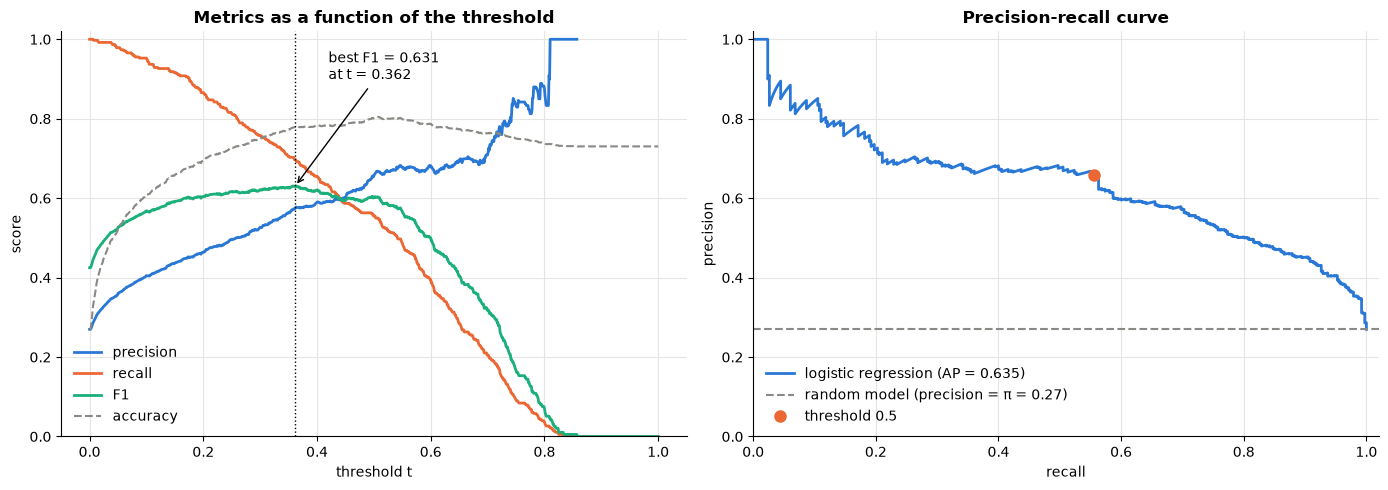

In [25]:
best_f1 = df_scores.f1.idxmax()
t_f1 = df_scores.threshold[best_f1]

prec_curve, rec_curve, _ = precision_recall_curve(y_valid, y_proba)
ap = average_precision_score(y_valid, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(df_scores.threshold, df_scores.precision, color=C_STAY, label="precision")
ax.plot(df_scores.threshold, df_scores.tpr, color=C_CHURN, label="recall")
ax.plot(df_scores.threshold, df_scores.f1, color=C_GREEN, label="F1")
ax.plot(df_scores.threshold, df_scores.accuracy, color=C_GRAY, linestyle="--", linewidth=1.5, label="accuracy")
ax.axvline(t_f1, color="black", linestyle=":", linewidth=1)
ax.annotate(f"best F1 = {df_scores.f1[best_f1]:.3f}\nat t = {t_f1:.3f}", (t_f1, df_scores.f1[best_f1]),
            xytext=(0.42, 0.9), textcoords="data", arrowprops=dict(arrowstyle="->", color="black"))
ax.set(xlabel="threshold t", ylabel="score", title="Metrics as a function of the threshold", ylim=(0, 1.02))
ax.legend(loc="lower left")

ax = axes[1]
ax.plot(rec_curve, prec_curve, color=C_STAY, label=f"logistic regression (AP = {ap:.3f})")
ax.axhline(y_valid.mean(), color=C_GRAY, linestyle="--", linewidth=1.5,
           label=f"random model (precision = π = {y_valid.mean():.2f})")
ax.plot(recall, precision, "o", color=C_CHURN, markersize=8, label="threshold 0.5")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall curve", xlim=(0, 1.02), ylim=(0, 1.02))
ax.legend(loc="lower left")

fig.tight_layout()
savefig(fig, "metrics_vs_threshold")
plt.show()

* Raising the threshold shrinks the circle: **recall** falls monotonically, **precision** rises (noisily at the far right, where only a handful of customers are still flagged).
* **F1** peaks at a threshold well below 0.5: with only 27 % churners, catching more of them is worth a few extra false alarms.
* The **precision-recall curve** shows the same trade-off without the threshold axis. Its baseline is the prevalence $\pi$ (a random model has precision $\pi$ at every recall). The **average precision (AP)** summarizes it in one number, similar to the AUC in section 8.

### 5.5 Choosing the threshold from business costs

Suppose a discount costs 1 unit and losing a customer costs 4 units: $c_{FP} = 1$, $c_{FN} = 4$. We look for the threshold that minimizes the total cost $c_{FP}\cdot\text{FP}(t) + c_{FN}\cdot\text{FN}(t)$.

**Theory.** If the score is a calibrated probability $p = P(y = 1 \mid x)$, flagging a customer has expected cost $(1 - p)\,c_{FP}$ and not flagging has expected cost $p\,c_{FN}$. Flagging is cheaper exactly when

$$
(1 - p)\,c_{FP} < p\,c_{FN} \iff p > t^* = \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{1}{1 + 4} = 0.2 .
$$

(With equal costs, $t^* = 0.5$: the default threshold is the one that maximizes *accuracy*.)

In [26]:
c_fp, c_fn = 1, 4
cost = c_fp * df_scores.fp + c_fn * df_scores.fn
best_cost = cost.idxmin()

print(f"theoretical optimum t* = {c_fp / (c_fp + c_fn):.3f}")
print(f"empirical optimum      = {df_scores.threshold[best_cost]:.3f}  (cost {cost[best_cost]})")
print(f"cost at t = 0.5        = {cost[df_scores.threshold.sub(0.5).abs().idxmin()]}")

theoretical optimum t* = 0.200
empirical optimum      = 0.173  (cost 561)
cost at t = 0.5        = 786


---
## 6. The ROC curve

Two rates describe what happens to the two classes separately:

$$
\text{TPR}(t) = \frac{\text{TP}}{\text{TP} + \text{FN}} = P\big(s(x) > t \;\big|\; y = 1\big)
\qquad
\text{FPR}(t) = \frac{\text{FP}}{\text{FP} + \text{TN}} = P\big(s(x) > t \;\big|\; y = 0\big)
$$

* **TPR** (true positive rate, = recall) is the fraction of *churners* above the threshold: the orange area to the right of $t$ in the histogram of section 3.1.
* **FPR** (false positive rate, $= 1 - \text{specificity}$) is the fraction of *stayers* above the threshold: the blue area to the right of $t$.

Because each rate only uses one class, **neither depends on the class balance**. The **ROC curve** (*receiver operating characteristic*, a name from radar engineering) plots $\big(\text{FPR}(t),\ \text{TPR}(t)\big)$ for all thresholds.

Let's first look at both rates as functions of the threshold. They come from the table `df_scores` of section 5.4.

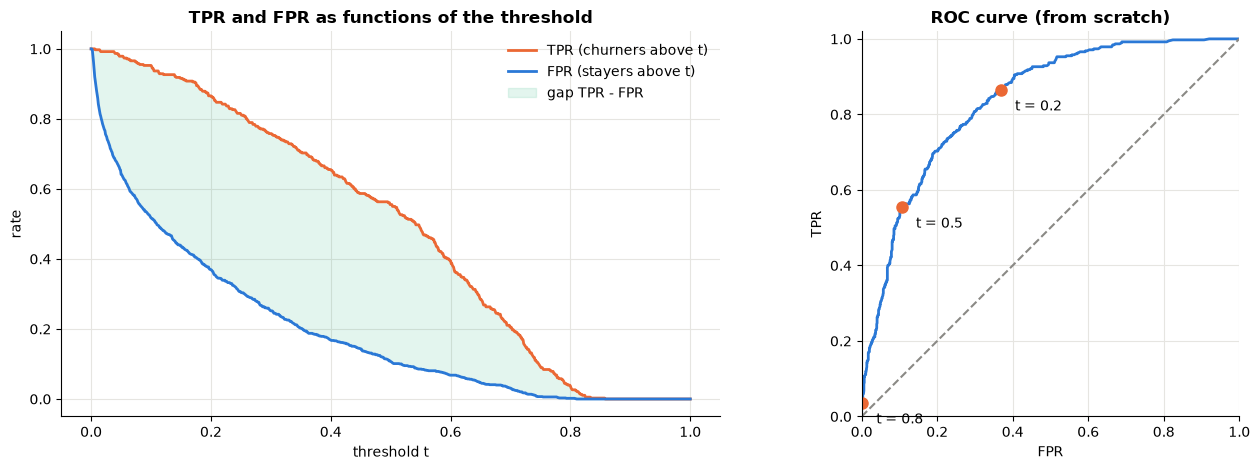

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.plot(df_scores.threshold, df_scores.tpr, color=C_CHURN, label="TPR (churners above t)")
ax.plot(df_scores.threshold, df_scores.fpr, color=C_STAY, label="FPR (stayers above t)")
ax.fill_between(df_scores.threshold, df_scores.fpr, df_scores.tpr, color=C_GREEN, alpha=0.12,
                label="gap TPR - FPR")
ax.set(xlabel="threshold t", ylabel="rate", title="TPR and FPR as functions of the threshold")
ax.legend()

ax = axes[1]
ax.plot(df_scores.fpr, df_scores.tpr, color=C_STAY)
ax.plot([0, 1], [0, 1], color=C_GRAY, linestyle="--", linewidth=1.5)
for t in [0.2, 0.5, 0.8]:
    row = df_scores.iloc[(df_scores.threshold - t).abs().idxmin()]
    ax.plot(row.fpr, row.tpr, "o", color=C_CHURN, markersize=8)
    ax.annotate(f"t = {t}", (row.fpr, row.tpr), xytext=(10, -15), textcoords="offset points")
ax.set(xlabel="FPR", ylabel="TPR", title="ROC curve (from scratch)", aspect="equal", xlim=(0, 1), ylim=(0, 1.02))

fig.tight_layout()
plt.show()

**Why do we want FPR to fall fast, and TPR to fall slowly?**

As the threshold increases, fewer customers are flagged, so *both* rates can only decrease. What we want is:

* **FPR should drop quickly**: already at a small threshold, almost all *stayers* should be below it (no false alarms). This happens when the stayers get low scores.
* **TPR should stay high for as long as possible**: the *churners* should still be above the threshold. This happens when the churners get high scores.

So the faster FPR falls *relative to* TPR, the larger the gap between the two curves, and the better the two classes are separated. The gap $J(t) = \text{TPR}(t) - \text{FPR}(t)$ is called **Youden's J statistic**; its maximum is the threshold at which the ROC curve is farthest above the diagonal. (For the ideal model of section 7 the gap reaches 1, for a random model it is always 0.)

In [28]:
J = df_scores.tpr - df_scores.fpr
best_j = J.idxmax()
print(f"max Youden J = {J[best_j]:.3f} at threshold {df_scores.threshold[best_j]:.3f} "
      f"(TPR = {df_scores.tpr[best_j]:.3f}, FPR = {df_scores.fpr[best_j]:.3f})")

max Youden J = 0.510 at threshold 0.257 (TPR = 0.808, FPR = 0.298)


---
## 7. Two reference models: random and ideal

To judge whether an ROC curve is good, we compare it with two extremes.

### 7.1 The random model

A random model ignores the input and gives every customer a score drawn uniformly from $[0, 1]$.

> **`np.random.rand` or `np.random.uniform`?** Both produce the same distribution: `np.random.rand(n)` is shorthand for `np.random.uniform(0, 1, n)`; `uniform` additionally lets you choose the bounds. Modern NumPy code uses a *generator* instead of the global functions, `rng = np.random.default_rng(seed)` and `rng.random(n)` (or `rng.uniform(0, 1, n)`), because the seed makes the results reproducible. We created `rng` in the setup cell.

Note that a model is always evaluated against the **true labels** `y_valid`, not against another model's predictions.

In [29]:
rng_random = np.random.default_rng(3)  # a separate generator, so this cell gives the same scores however often it runs
y_score_random = rng_random.random(len(y_valid))

print("accuracy of the random model at t = 0.5:", ((y_score_random > 0.5) == y_valid).mean().round(3))

df_scores_random = scores_table(y_valid, y_score_random)
df_scores_random[::100][["threshold", "tp", "fp", "fn", "tn", "tpr", "fpr"]].round(3)

accuracy of the random model at t = 0.5: 0.482


,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,380,1029,0,0,1.000,1.000
100,0.1,342,922,38,107,0.900,0.896
200,0.2,304,819,76,210,0.800,0.796
300,0.3,266,726,114,303,0.700,0.706
400,0.4,222,628,158,401,0.584,0.610
500,0.5,181,531,199,498,0.476,0.516
600,0.6,149,417,231,612,0.392,0.405
700,0.7,116,309,264,720,0.305,0.300
800,0.8,85,198,295,831,0.224,0.192
900,0.9,43,102,337,927,0.113,0.099


**What should we expect?** The score $U \sim \text{Uniform}(0, 1)$ is independent of the label, so for both classes

$$
\text{TPR}(t) = P(U > t \mid y = 1) = P(U > t) = 1 - t,
\qquad
\text{FPR}(t) = P(U > t \mid y = 0) = 1 - t .
$$

Both rates fall **together** along the line $1 - t$: every threshold that removes a fraction of false alarms removes the same fraction of true detections. Then $\text{TPR} = \text{FPR}$, so the ROC curve of a random model is the **diagonal**. A useful model must do better: TPR above FPR, i.e. a gap between the curves.

### 7.2 The ideal model

An ideal model **ranks every positive above every negative**. Then there is a threshold $t^*$ between the highest negative score and the lowest positive score with

$$
\text{FPR}(t^*) = 0 \quad (\text{FP} = 0) \qquad\text{and}\qquad \text{TPR}(t^*) = 1 \quad (\text{FN} = 0),
$$

and at this threshold accuracy, precision and recall are all 100 %.

Such a model does not exist for real churn data (no feature set predicts human behavior perfectly). It is a *thought experiment*, and we can simulate it by **constructing** the scores: sort the customers so that all negatives come first, and give them increasing scores between 0 and 1. With $n_-$ negatives out of $n$ customers, the negatives occupy the scores in $[0, n_-/n]$ and the positives those in $(n_-/n, 1]$, so the perfect threshold is $t^* = n_-/n \approx 0.73$. That value is a consequence of how we built the scores, not a property of ideal models: any scores with a gap between the classes would do.

In [30]:
num_pos = (y_valid == 1).sum()
num_neg = (y_valid == 0).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])     # all negatives first, then all positives
y_score_ideal = np.linspace(0, 1, len(y_ideal))     # increasing scores

print(f"positives: {num_pos}, negatives: {num_neg}, n_- / n = {num_neg / (num_neg + num_pos):.4f}")

# Any threshold in the gap between the highest negative and the lowest positive score is perfect
t_star = (y_score_ideal[y_ideal == 0].max() + y_score_ideal[y_ideal == 1].min()) / 2
y_hat_ideal = (y_score_ideal > t_star).astype(int)
print(f"at t* = {t_star:.4f}: TPR = {recall_score(y_ideal, y_hat_ideal):.3f}, "
      f"FPR = {1 - recall_score(y_ideal, y_hat_ideal, pos_label=0):.3f}, "
      f"accuracy = {accuracy_score(y_ideal, y_hat_ideal):.3f}")

df_scores_ideal = scores_table(y_ideal, y_score_ideal)

positives: 380, negatives: 1029, n_- / n = 0.7303
at t* = 0.7305: TPR = 1.000, FPR = 0.000, accuracy = 1.000


### 7.3 Comparing the three models

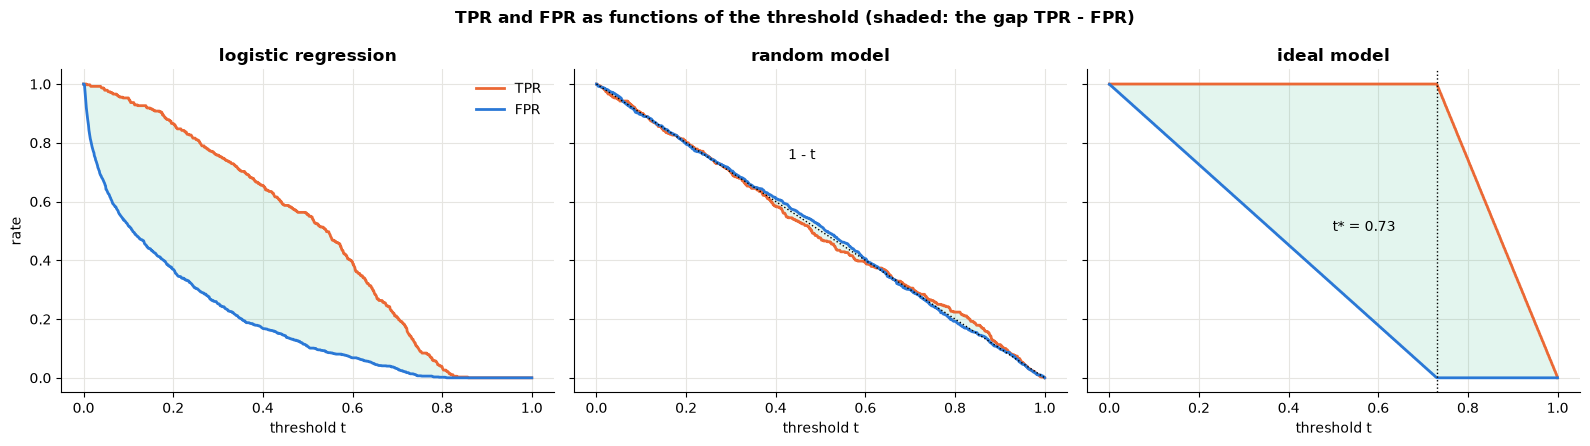

In [31]:
models = [
    ("logistic regression", df_scores, C_STAY),
    ("random model", df_scores_random, C_GRAY),
    ("ideal model", df_scores_ideal, C_GREEN),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, d, color) in zip(axes, models):
    ax.plot(d.threshold, d.tpr, color=C_CHURN, label="TPR")
    ax.plot(d.threshold, d.fpr, color=C_STAY, label="FPR")
    ax.fill_between(d.threshold, d.fpr, d.tpr, color=C_GREEN, alpha=0.12)
    ax.set(title=name, xlabel="threshold t")
axes[0].set_ylabel("rate")
axes[0].legend()
axes[1].plot([0, 1], [1, 0], color="black", linestyle=":", linewidth=1)
axes[1].annotate("1 - t", (0.35, 0.65), xytext=(25, 20), textcoords="offset points")
axes[2].axvline(t_star, color="black", linestyle=":", linewidth=1)
axes[2].annotate(f"t* = {t_star:.2f}", (t_star, 0.5), xytext=(-75, 0), textcoords="offset points")
fig.suptitle("TPR and FPR as functions of the threshold (shaded: the gap TPR - FPR)", fontweight="bold")
fig.tight_layout()
savefig(fig, "tpr_fpr_three_models")
plt.show()

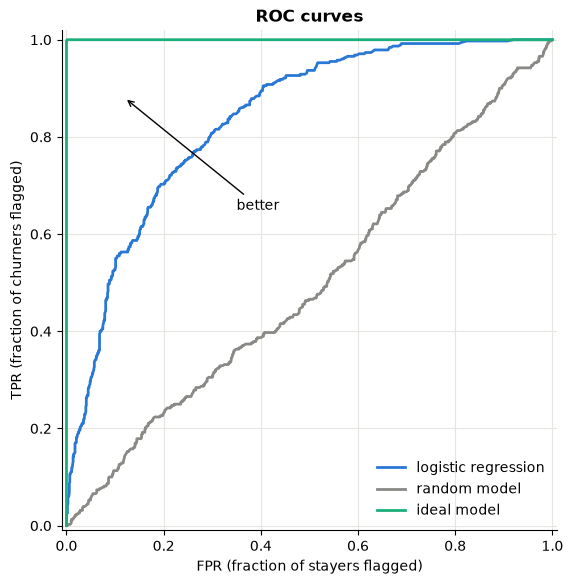

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for name, d, color in models:
    ax.plot(d.fpr, d.tpr, color=color, label=name)
ax.set(xlabel="FPR (fraction of stayers flagged)", ylabel="TPR (fraction of churners flagged)",
       title="ROC curves", aspect="equal", xlim=(-0.01, 1.01), ylim=(-0.01, 1.02))
ax.annotate("better", xy=(0.12, 0.88), xytext=(0.35, 0.65), arrowprops=dict(arrowstyle="->", color="black"))
ax.legend(loc="lower right")
savefig(fig, "roc_comparison")
plt.show()

The ideal curve goes straight up to the top-left corner $(0, 1)$ (no false alarms, all churners found), the random model follows the diagonal, and our model lies in between. **The closer to the top-left corner, the better.**

**A side note: what is `df_scores_ideal.tpr.mean()`?** Averaging TPR over equally spaced thresholds approximates $\int_0^1 \text{TPR}(t)\,dt$, the area under the *TPR-vs-threshold* curve. This is **not** the AUC (which is the area under TPR-vs-*FPR*). For scores in $[0, 1]$ it has a neat meaning of its own:

$$
\int_0^1 \text{TPR}(t)\,dt = \int_0^1 P(S > t \mid y = 1)\,dt = \mathbb{E}[S \mid y = 1],
$$

the **average score of the positives**. For the ideal model they are spread uniformly over $[0.73, 1]$, so the value is $\approx (0.73 + 1)/2 \approx 0.865$.

In [33]:
print("mean of TPR over the thresholds:", df_scores_ideal.tpr.mean().round(4))
print("average score of the positives :", y_score_ideal[y_ideal == 1].mean().round(4))

mean of TPR over the thresholds: 0.865
average score of the positives : 0.8654


### 7.4 ROC curves with scikit-learn

`roc_curve` computes the same curve more efficiently and exactly. Differences from our version:

* it uses only the **distinct score values** as thresholds (every other threshold gives one of the same points), so there are far fewer points;
* it predicts positive when $s \geq t$ (we used $s > t$; this only matters for ties);
* the first threshold is $+\infty$, so that the curve starts at $(0, 0)$.

logistic regression :   398 thresholds, the first one is inf
random model        :   584 thresholds, the first one is inf
ideal model         :     4 thresholds, the first one is inf


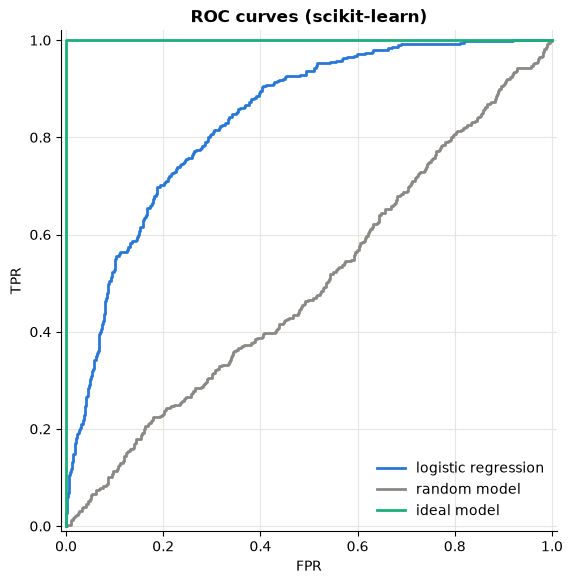

In [34]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for name, (y_true_m, y_score_m), color in [
    ("logistic regression", (y_valid, y_proba), C_STAY),
    ("random model", (y_valid, y_score_random), C_GRAY),
    ("ideal model", (y_ideal, y_score_ideal), C_GREEN),
]:
    fpr, tpr, thr = roc_curve(y_true=y_true_m, y_score=y_score_m)
    print(f"{name:20s}: {len(thr):5d} thresholds, the first one is {thr[0]}")
    ax.plot(fpr, tpr, color=color, label=name)
ax.set(xlabel="FPR", ylabel="TPR", title="ROC curves (scikit-learn)", aspect="equal",
       xlim=(-0.01, 1.01), ylim=(-0.01, 1.02))
ax.legend(loc="lower right")
plt.show()

---
## 8. AUC: the area under the ROC curve

The ROC curve shows all thresholds at once; to compare models with **one number**, we take the area under it:

$$
\text{AUC} = \int_0^1 \text{TPR}\; d(\text{FPR}) .
$$

* ideal model: AUC = 1 (the curve encloses the whole unit square),
* random model: AUC ≈ 0.5 (the triangle under the diagonal),
* AUC < 0.5: worse than random; the model ranks the wrong way, and flipping its predictions ($s \to 1 - s$) gives AUC $= 1 - \text{AUC} > 0.5$.

In [35]:
print("roc_auc_score")
print(f"  logistic regression: {roc_auc_score(y_valid, y_proba):.4f}")
print(f"  random model       : {roc_auc_score(y_valid, y_score_random):.4f}")
print(f"  ideal model        : {roc_auc_score(y_ideal, y_score_ideal):.4f}")

# The area under our from-scratch curve with the trapezoidal rule (sklearn.metrics.auc needs sorted x values)
d = df_scores.sort_values(["fpr", "tpr"])
print(f"\ntrapezoidal area under the from-scratch ROC curve: {auc(d.fpr, d.tpr):.4f}")

roc_auc_score
  logistic regression: 0.8362
  random model       : 0.4974
  ideal model        : 1.0000

trapezoidal area under the from-scratch ROC curve: 0.8362


The random model's AUC is not *exactly* 0.5 because the scores are random: on a finite sample, its AUC is itself a random variable centered at 0.5 with standard deviation

$$
\sigma_{\text{AUC}} = \sqrt{\frac{n_+ + n_- + 1}{12\, n_+ n_-}} = \sqrt{\frac{1410}{12 \cdot 380 \cdot 1029}} \approx 0.017
$$

(the null distribution of the Mann-Whitney statistic, see 8.1). Values between roughly 0.47 and 0.53 are therefore normal for a model that knows nothing.

### 8.1 The probabilistic interpretation, and why it holds

AUC has a beautiful interpretation:

> **AUC is the probability that a randomly chosen positive example gets a higher score than a randomly chosen negative example.**
>
> $$\text{AUC} = P(S_+ > S_-) + \tfrac{1}{2}\,P(S_+ = S_-)$$
>
> where $S_+$ is the score of a random positive and $S_-$ the score of a random negative (ties count one half).

So an AUC of 0.84 means: pick a churner and a non-churner at random; in 84 % of the cases the model gives the churner the higher churn probability. AUC measures **how well the model ranks**, regardless of any threshold.

**Proof (discrete version).** Sort all $n$ examples by score, from highest to lowest, and lower the threshold step by step, passing one example at a time:

* passing a **positive** moves one more positive above the threshold: TPR increases by $1/n_+$, so the curve takes a step **up** of height $1/n_+$;
* passing a **negative** increases FPR by $1/n_-$: the curve takes a step **right** of width $1/n_-$.

The ROC curve is therefore a staircase, and only the **right** steps add area. When we pass the negative $j$, the curve is at height $\text{TPR} = k_j / n_+$, where $k_j$ is the number of positives that were already passed, i.e. the number of positives scored **higher** than negative $j$. The area of that column is

$$
\frac{1}{n_-}\cdot\frac{k_j}{n_+}, \qquad\text{so}\qquad
\text{AUC} = \sum_{j=1}^{n_-} \frac{k_j}{n_+ n_-} = \frac{\#\{(i, j):\ s^+_i > s^-_j\}}{n_+ \cdot n_-} .
$$

The right-hand side is the fraction of all (positive, negative) pairs that the model orders correctly: exactly the probability that a random positive outscores a random negative. If a positive and a negative have the **same** score, the threshold passes both at once and the curve moves diagonally; the triangle under that diagonal step is half of the rectangle, which is where the $\tfrac{1}{2}$ for ties comes from. $\blacksquare$

**Continuous version.** With $F_+, F_-$ the score distributions of the two classes and $f_-$ the density of the negatives, $\text{TPR}(t) = 1 - F_+(t)$ and $\text{FPR}(t) = 1 - F_-(t)$, so $d\,\text{FPR} = -f_-(t)\,dt$. As FPR runs from 0 to 1, $t$ runs from $+\infty$ to $-\infty$:

$$
\text{AUC} = \int_{+\infty}^{-\infty} \big(1 - F_+(t)\big)\,\big(-f_-(t)\big)\,dt
= \int_{-\infty}^{+\infty} P(S_+ > t)\, f_-(t)\, dt = P(S_+ > S_-),
$$

the last step being the law of total probability, conditioning on the value $t$ of $S_-$.

The count $\#\{(i, j):\ s^+_i > s^-_j\}$ is the **Mann-Whitney U statistic**, so $\text{AUC} = U / (n_+ n_-)$: the AUC is the normalized statistic of a classical rank test.

The figure illustrates the proof with 4 positives and 4 negatives.

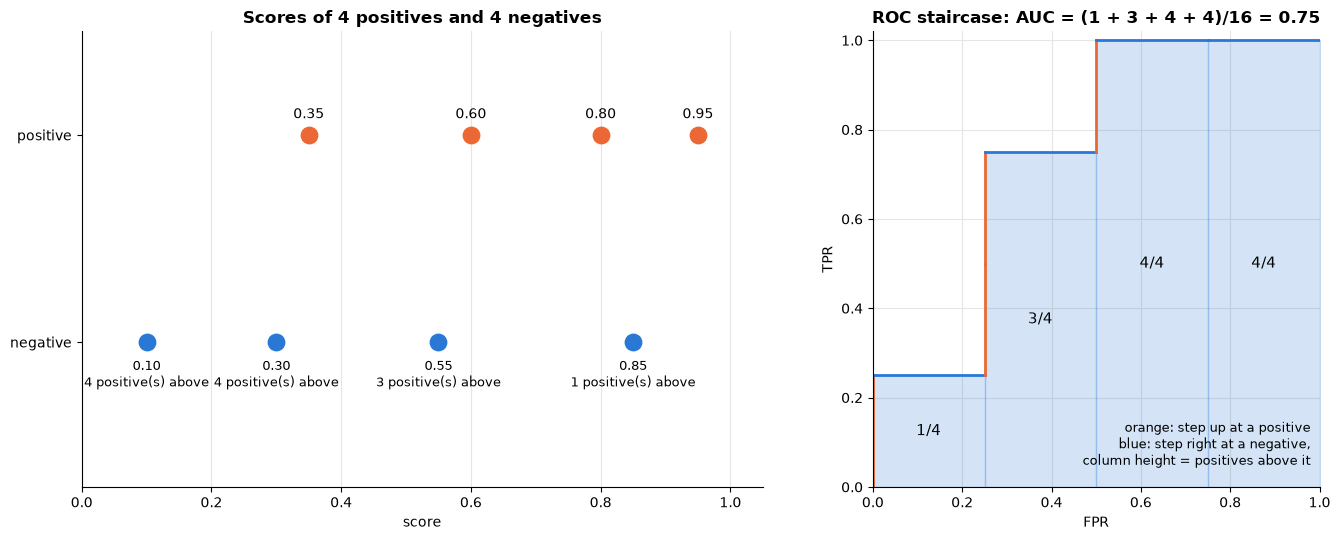

pairs correctly ordered: 12 of 16


In [36]:
toy_pos = np.array([0.95, 0.80, 0.60, 0.35])
toy_neg = np.array([0.85, 0.55, 0.30, 0.10])
toy_scores = np.concatenate([toy_pos, toy_neg])
toy_labels = np.array([1] * 4 + [0] * 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})

# Left: the scores on a number line
ax = axes[0]
ax.scatter(toy_pos, np.ones(4), s=140, color=C_CHURN, zorder=3, label="positives (churn)")
ax.scatter(toy_neg, np.zeros(4), s=140, color=C_STAY, zorder=3, label="negatives (stay)")
for s in toy_pos:
    ax.annotate(f"{s:.2f}", (s, 1), xytext=(0, 12), textcoords="offset points", ha="center")
for s in toy_neg:
    k = (toy_pos > s).sum()
    ax.annotate(f"{s:.2f}\n{k} positive(s) above", (s, 0), xytext=(0, -32), textcoords="offset points",
                ha="center", fontsize=9)
ax.set(yticks=[0, 1], yticklabels=["negative", "positive"], ylim=(-0.7, 1.5), xlim=(0, 1.05),
       xlabel="score", title="Scores of 4 positives and 4 negatives")
ax.grid(axis="y", visible=False)

# Right: the staircase ROC curve, sweeping the threshold from high to low
ax = axes[1]
x, y = 0.0, 0.0
for i in np.argsort(-toy_scores):
    if toy_labels[i] == 1:
        ax.plot([x, x], [y, y + 0.25], color=C_CHURN)
        y += 0.25
    else:
        ax.fill_between([x, x + 0.25], 0, y, color=C_STAY, alpha=0.2)
        ax.text(x + 0.125, y / 2, f"{int(y * 4)}/4", ha="center", va="center", fontsize=11)
        ax.plot([x, x + 0.25], [y, y], color=C_STAY)
        x += 0.25
toy_auc = roc_auc_score(toy_labels, toy_scores)
ax.set(xlabel="FPR", ylabel="TPR", aspect="equal", xlim=(0, 1), ylim=(0, 1.02),
       title=f"ROC staircase: AUC = (1 + 3 + 4 + 4)/16 = {toy_auc}")
ax.text(0.98, 0.04, "orange: step up at a positive\nblue: step right at a negative,\n"
        "column height = positives above it", ha="right", va="bottom", fontsize=9)

fig.tight_layout()
savefig(fig, "auc_staircase")
plt.show()

print("pairs correctly ordered:", (toy_pos[:, None] > toy_neg[None, :]).sum(), "of", 4 * 4)

### 8.2 Checking the interpretation on the churn model

Three ways to compute $P(S_+ > S_-)$, all compared with `roc_auc_score`:

1. **Monte Carlo**: draw many random (positive, negative) pairs and count how often the positive wins.
2. **Exactly**: compare *all* $n_+ \cdot n_- = 380 \times 1029 \approx 391{,}000$ pairs (ties count ½).
3. **Mann-Whitney U** from `scipy`.

In [37]:
pos = y_proba[y_valid == 1]
neg = y_proba[y_valid == 0]

# 1. Monte Carlo with a loop (easy to read) ...
n_draws = 10_000
success = 0
for _ in range(n_draws):
    if pos[rng.integers(len(pos))] > neg[rng.integers(len(neg))]:
        success += 1
print(f"Monte Carlo, loop      ({n_draws:>7,} pairs): {success / n_draws:.4f}")

# ... and vectorized with NumPy (fast, so we can afford many more draws)
n_draws = 1_000_000
pos_idx = rng.integers(0, len(pos), size=n_draws)
neg_idx = rng.integers(0, len(neg), size=n_draws)
print(f"Monte Carlo, vectorized ({n_draws:>,} pairs): {(pos[pos_idx] > neg[neg_idx]).mean():.4f}")

# 2. All pairs: a (n_pos x n_neg) comparison matrix
greater = pos[:, None] > neg[None, :]
ties = pos[:, None] == neg[None, :]
auc_pairs = greater.mean() + 0.5 * ties.mean()
print(f"all {greater.size:,} pairs (exact)        : {auc_pairs:.6f}")

# 3. Mann-Whitney U
u = mannwhitneyu(pos, neg).statistic
print(f"Mann-Whitney U / (n+ n-)            : {u / (len(pos) * len(neg)):.6f}")

print(f"roc_auc_score                       : {roc_auc_score(y_valid, y_proba):.6f}")
assert np.isclose(auc_pairs, roc_auc_score(y_valid, y_proba))

Monte Carlo, loop      ( 10,000 pairs): 0.8393
Monte Carlo, vectorized (1,000,000 pairs): 0.8356
all 391,020 pairs (exact)        : 0.836200
Mann-Whitney U / (n+ n-)            : 0.836200
roc_auc_score                       : 0.836200


The Monte Carlo estimates fluctuate around the true value (their standard error is $\sqrt{\text{AUC}(1-\text{AUC})/N}$, about 0.004 for $N = 10{,}000$), while the exact pair count and the Mann-Whitney statistic match `roc_auc_score` to all digits.

**Consequences of the interpretation**

* AUC depends only on the **ranking** of the scores. Any strictly increasing transformation of the scores (squaring probabilities, using log-odds instead of probabilities, ...) leaves it unchanged.
* AUC does **not depend on a threshold** and is **insensitive to the class balance** (it compares positives with negatives, never counts them against each other). This makes it a good metric for comparing models on imbalanced data.
* The flip side: AUC says nothing about whether the probabilities are *calibrated* or which threshold to use. Those questions need the tools of section 5.

In [38]:
log_odds = np.log(y_proba / (1 - y_proba))
print(f"AUC of the probabilities      : {roc_auc_score(y_valid, y_proba):.6f}")
print(f"AUC of probabilities cubed    : {roc_auc_score(y_valid, y_proba ** 3):.6f}")
print(f"AUC of the log-odds           : {roc_auc_score(y_valid, log_odds):.6f}")

AUC of the probabilities      : 0.836200
AUC of probabilities cubed    : 0.836200
AUC of the log-odds           : 0.836200


---
## 9. k-fold cross-validation

So far every number came from **one** validation set of 1,409 customers. How much would the AUC change with a different split? A single split cannot tell us. **k-fold cross-validation** answers this:

1. Split the full training data (`df_train_full`, train + validation, 80 % of all customers) into $K$ equally sized **folds**.
2. For $k = 1, \dots, K$: train on the other $K - 1$ folds, evaluate on fold $k$, record the score $A_k$.
3. Report the mean and the standard deviation:

$$
\bar A = \frac{1}{K}\sum_{k=1}^{K} A_k, \qquad
s = \sqrt{\frac{1}{K}\sum_{k=1}^{K} \big(A_k - \bar A\big)^2} .
$$

Every example is used for validation exactly once and for training $K - 1$ times. The **test set stays untouched** during the whole procedure.

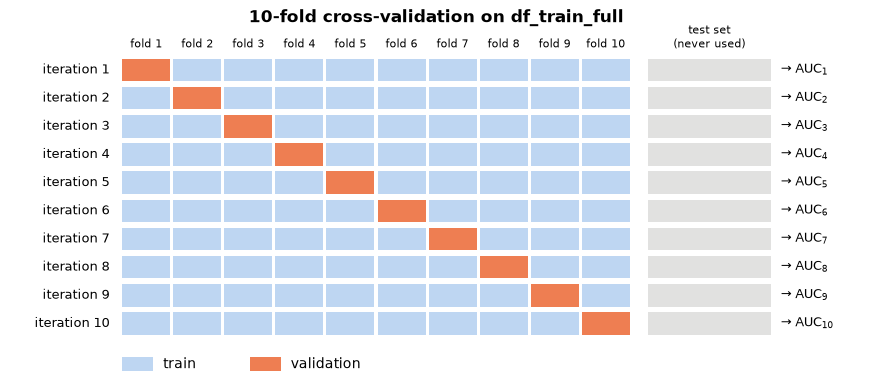

In [39]:
K = 10
fig, ax = plt.subplots(figsize=(11, 4.5))
for it in range(K):
    for fold in range(K):
        is_val = fold == it
        ax.add_patch(Rectangle((fold, K - 1 - it), 0.94, 0.8, facecolor=C_CHURN if is_val else C_STAY,
                               alpha=0.85 if is_val else 0.3, linewidth=0))
    ax.add_patch(Rectangle((K + 0.3, K - 1 - it), 2.4, 0.8, facecolor=C_GRAY, alpha=0.25, linewidth=0))
    ax.text(-0.25, K - 1 - it + 0.4, f"iteration {it + 1}", ha="right", va="center", fontsize=9)
    ax.text(K + 2.9, K - 1 - it + 0.4, f"→ AUC$_{{{it + 1}}}$", ha="left", va="center", fontsize=9)
for fold in range(K):
    ax.text(fold + 0.47, K + 0.2, f"fold {fold + 1}", ha="center", fontsize=8)
ax.text(K + 1.5, K + 0.2, "test set\n(never used)", ha="center", fontsize=8)
ax.add_patch(Rectangle((0, -1.3), 0.6, 0.5, facecolor=C_STAY, alpha=0.3))
ax.text(0.8, -1.05, "train", va="center")
ax.add_patch(Rectangle((2.5, -1.3), 0.6, 0.5, facecolor=C_CHURN, alpha=0.85))
ax.text(3.3, -1.05, "validation", va="center")
ax.set(xlim=(-2.2, K + 4.5), ylim=(-1.5, K + 0.8), title=f"{K}-fold cross-validation on df_train_full")
ax.axis("off")
savefig(fig, "kfold_diagram")
plt.show()

### 9.1 Training and prediction functions

To repeat training many times we wrap the code from section 2 into two functions. `C` is the inverse regularization strength of logistic regression; it is explained in 9.3.

In [40]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient="records"))
    model = LogisticRegression(C=C, max_iter=5000, random_state=SEED).fit(X_tr, y_tr)
    return dv, model


def predict(df_new, dv, model):
    X_new = dv.transform(df_new[features].to_dict(orient="records"))
    return model.predict_proba(X_new)[:, 1]


# Sanity check: reproduces the model of section 2
dv_check, model_check = train(df_train, y_train)
print(f"validation AUC: {roc_auc_score(y_valid, predict(df_valid, dv_check, model_check)):.4f}")

validation AUC: 0.8362


### 9.2 Cross-validated AUC

`KFold.split` yields the row positions of the training and validation part for each iteration. We use new variable names (`df_tr`, `df_va`) so that the train/validation split of section 2 is not overwritten.

In [41]:
kfold = KFold(n_splits=K, shuffle=True, random_state=SEED)

aucs = []
for train_idx, val_idx in kfold.split(df_train_full):
    df_tr, df_va = df_train_full.iloc[train_idx], df_train_full.iloc[val_idx]
    dv_k, model_k = train(df_tr, df_tr.Churn.values)
    aucs.append(roc_auc_score(df_va.Churn.values, predict(df_va, dv_k, model_k)))

print("AUC per fold:", np.round(aucs, 3))
print(f"AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

AUC per fold: [0.85  0.842 0.859 0.833 0.825 0.841 0.843 0.825 0.846 0.861]
AUC = 0.843 ± 0.012


The AUC varies between folds by about ±0.01 just because of *which* customers end up in the validation fold. Our single validation AUC of 0.836 from section 8 is one draw from this distribution. Any difference between two models that is much smaller than this spread should not be taken seriously.

### 9.3 Tuning the regularization parameter `C`

scikit-learn's logistic regression minimizes

$$
\frac{1}{2}\lVert \mathbf w \rVert^2 + C \sum_{i=1}^{n} \Big[-y_i \log s(x_i) - (1 - y_i)\log\big(1 - s(x_i)\big)\Big] .
$$

`C` weighs the data term against the penalty on the weights: a **small `C` means strong regularization** (weights pushed toward 0, simpler model), a large `C` means weak regularization. We pick `C` by cross-validation: compute the mean CV AUC for each candidate and choose the best one.

In [42]:
C_values = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]

results = []
for C in C_values:
    aucs_c = []
    for train_idx, val_idx in kfold.split(df_train_full):
        df_tr, df_va = df_train_full.iloc[train_idx], df_train_full.iloc[val_idx]
        dv_k, model_k = train(df_tr, df_tr.Churn.values, C=C)
        aucs_c.append(roc_auc_score(df_va.Churn.values, predict(df_va, dv_k, model_k)))
    results.append((C, np.mean(aucs_c), np.std(aucs_c)))

df_cv = pd.DataFrame(results, columns=["C", "auc_mean", "auc_std"])
best_C = df_cv.C[df_cv.auc_mean.idxmax()]
print(f"best C = {best_C}")
df_cv.round(4)

best C = 0.5


,C,auc_mean,auc_std
0,0.0001,0.8110,0.0119
1,0.0010,0.8261,0.0118
2,0.0100,0.8408,0.0118
3,0.0500,0.8423,0.0116
4,0.1000,0.8425,0.0117
5,0.5000,0.8426,0.0117
6,1.0000,0.8426,0.0117
7,5.0000,0.8424,0.0116
8,10.0000,0.8423,0.0116


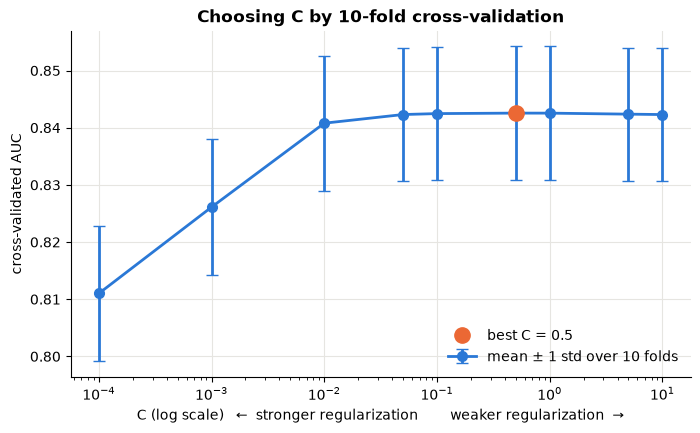

In [43]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(df_cv.C, df_cv.auc_mean, yerr=df_cv.auc_std, color=C_STAY, marker="o", markersize=7, capsize=4,
            label="mean ± 1 std over 10 folds")
ax.plot(best_C, df_cv.auc_mean.max(), "o", color=C_CHURN, markersize=11, zorder=3, label=f"best C = {best_C}")
ax.set_xscale("log")
ax.set(xlabel="C (log scale)   ←  stronger regularization        weaker regularization  →",
       ylabel="cross-validated AUC", title="Choosing C by 10-fold cross-validation")
ax.legend(loc="lower right")
savefig(fig, "cv_tuning_C")
plt.show()

Strong regularization ($C \le 0.001$) clearly hurts: the weights cannot become large enough to fit the data. From $C = 0.01$ on the mean AUC is practically constant: the differences are in the third or fourth decimal, **far smaller than the fold-to-fold standard deviation** of about 0.012. Any of these values is a good choice; we take the one with the highest mean. (A common alternative, the *one-standard-error rule*, picks the most regularized model whose mean is within one standard error $s/\sqrt{K}$ of the best.)

### 9.4 Final model: train on all training data, evaluate once on the test set

Now that all decisions are made (features, model, `C`, threshold 0.5), we train **one** model on the full training data (train + validation) and evaluate it **once** on the test set, which was never used before.

In [44]:
dv_final, model_final = train(df_train_full, y_train_full, C=best_C)
y_proba_test = predict(df_test, dv_final, model_final)
y_pred_test = (y_proba_test > 0.5).astype(int)
y_dummy_test = np.zeros_like(y_test)


def all_metrics(y_true, y_hat, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat),
        "F1": f1_score(y_true, y_hat),
        "ROC AUC": roc_auc_score(y_true, y_score),
    }


df_results = pd.DataFrame({
    "always 'stay' (baseline)": all_metrics(y_test, y_dummy_test, y_dummy_test),
    f"logistic regression (C = {best_C})": all_metrics(y_test, y_pred_test, y_proba_test),
}).T
df_results.round(3)

,accuracy,precision,recall,F1,ROC AUC
always 'stay' (baseline),0.753,0.000,0.000,0.000,0.500
logistic regression (C = 0.5),0.813,0.631,0.589,0.609,0.858


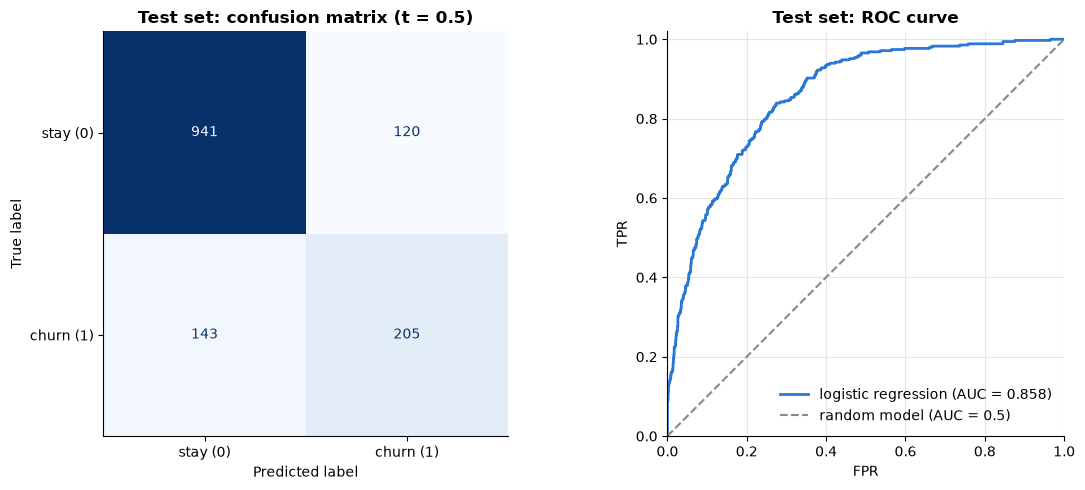

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=labels, cmap="Blues",
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Test set: confusion matrix (t = 0.5)")
axes[0].grid(False)

fpr_test, tpr_test, _ = roc_curve(y_test, y_proba_test)
ax = axes[1]
ax.plot(fpr_test, tpr_test, color=C_STAY, label=f"logistic regression (AUC = {roc_auc_score(y_test, y_proba_test):.3f})")
ax.plot([0, 1], [0, 1], color=C_GRAY, linestyle="--", linewidth=1.5, label="random model (AUC = 0.5)")
ax.set(xlabel="FPR", ylabel="TPR", title="Test set: ROC curve", aspect="equal", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")

fig.tight_layout()
savefig(fig, "test_performance")
plt.show()

The test AUC lies close to the cross-validated estimate (a little more than one fold standard deviation above its mean), so the CV estimate was realistic and we did not overfit our modeling decisions to the validation data. The test numbers differ slightly from the validation numbers of sections 3–8 because the model is trained on more data and evaluated on different customers.

### 9.5 When should we use k-fold cross-validation?

**Use it when**

* the dataset is **small or medium-sized** (up to tens of thousands of rows), so that a single validation set is small and its score noisy;
* you need an **uncertainty estimate** (the ± part), e.g. to decide whether model A is really better than model B;
* you **tune hyperparameters** (like `C`) or select features or models: averaging over folds makes the choice less dependent on one lucky or unlucky split;
* training is **cheap enough** to repeat $K$ times.

**A single train/validation split is usually enough when**

* the dataset is **large** (hundreds of thousands of rows or more): the validation score is already precise;
* training is **expensive** (deep neural networks): $K$ trainings cost $K$ times as much.

**Use a variant of k-fold when**

* the classes are **imbalanced**: `StratifiedKFold` keeps the churn rate the same in every fold;
* the data have **groups** (several rows per customer, patient, ...): `GroupKFold` keeps a group inside one fold, otherwise the model is validated on "known" examples;
* the data are a **time series**: `TimeSeriesSplit` always validates on data that come *after* the training data, never on the past;
* you need an unbiased estimate *after* tuning on the same data: **nested cross-validation** (an inner CV loop for tuning inside an outer loop for evaluation).

Typical values are $K = 5$ or $K = 10$. Larger $K$ means more training data per fold (less pessimistic estimate) but more computation; $K = n$ is *leave-one-out* cross-validation.

In all cases, **the test set is not part of cross-validation**: it is used once, at the very end, as above.

---
## 10. Summary

| Metric | Formula | Question it answers | Watch out |
|--------|---------|---------------------|-----------|
| Accuracy | $\dfrac{\text{TP}+\text{TN}}{n}$ | What fraction of all predictions is correct? | Misleading on imbalanced data; compare with $\max(\pi, 1-\pi)$ |
| Precision | $\dfrac{\text{TP}}{\text{TP}+\text{FP}}$ | When the model raises an alarm, how often is it right? | Can be made high by flagging very few examples |
| Recall / TPR | $\dfrac{\text{TP}}{\text{TP}+\text{FN}}$ | Which fraction of the positives does the model find? | 100 % for "everything is positive" |
| Specificity / TNR | $\dfrac{\text{TN}}{\text{TN}+\text{FP}}$ | Which fraction of the negatives is correctly ignored? | |
| FPR | $\dfrac{\text{FP}}{\text{FP}+\text{TN}} = 1 - \text{specificity}$ | Which fraction of the negatives raises a false alarm? | |
| F1 | $\dfrac{2PR}{P+R} = \dfrac{2\,\text{TP}}{2\,\text{TP}+\text{FP}+\text{FN}}$ | Are precision *and* recall both good? | Ignores TN; depends on the threshold |
| ROC AUC | $\int \text{TPR}\, d\,\text{FPR} = P(S_+ > S_-)$ | How well does the model *rank* positives above negatives? | Threshold-free: says nothing about calibration or the best threshold |
| Average precision | area under the PR curve | Ranking quality, focused on the positive class | Its baseline is $\pi$, not 0.5 |

**Key takeaways**

1. **Always compare with a baseline.** A 73 % accurate model can be useless.
2. **Accuracy, precision and recall are accuracies on different parts of the data** (everybody, the predicted positives, the actual positives).
3. **The threshold is a business decision.** Precision and recall trade off against each other; choose $t$ from the costs of false positives and false negatives ($t^* = c_{FP}/(c_{FP}+c_{FN})$ for calibrated probabilities).
4. **ROC AUC measures ranking quality**: the probability that a random positive outscores a random negative.
5. **Report uncertainty.** k-fold cross-validation turns one noisy number into a mean ± standard deviation, and keeps the test set clean for one final check.

### References

* T. Fawcett (2006). *An introduction to ROC analysis.* Pattern Recognition Letters 27, 861–874.
* J. A. Hanley and B. J. McNeil (1982). *The meaning and use of the area under a receiver operating characteristic (ROC) curve.* Radiology 143, 29–36.
* scikit-learn user guide: [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html) and [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
* Dataset: [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM sample data, via Kaggle).